# GridVision — Model 1: Month-End Electricity Bill Prediction
**End-to-end V1 notebook:** data validation, EDA, daily aggregation, leakage-safe feature engineering, chronological model selection/tuning, evaluation, and `.pkl` export for a future FastAPI API and dashboard.

## Product rules encoded
- Input readings are **15-minute interval energy in kWh**; aggregate by **summing** readings (do not multiply by 0.25).
- Default tariff: **₹10/kWh** (prototype energy-charge estimate only).
- First seven days are onboarding; predictions begin from **Day 8**.
- At each forecast origin (end of a day), predict consumption for the **following days through month-end**.
- Estimated month-end bill = (actual cycle consumption so far + predicted remaining consumption) × tariff.
- Split and tune chronologically. Do not randomly split time-series rows.

## Before running
1. Put the historical CSV/Parquet file in the working directory, or set `DATA_PATH` below.
2. Confirm the timestamp column and whether each meter column represents a household.
3. Confirm timezone and billing-cycle assumptions. This V1 uses calendar months.
4. This notebook creates a model artifact and metadata file. The API should load the `.pkl` and use the **same feature-generation logic**.

# First lookup

In [ ]:
from pathlib import Path
import json, pickle, warnings, itertools, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

In [ ]:
df = pd.read_csv(
"Data/Demo.txt",
sep=";",
decimal=",",
parse_dates=[0],
index_col=0
)

In [ ]:
df.sample(10)

,MT_001,MT_002,MT_003,MT_004,MT_005,MT_006,MT_007,MT_008,MT_009,MT_010,MT_011,MT_012,MT_013,MT_014,MT_015,MT_016,MT_017,MT_018,MT_019,MT_020,MT_021,MT_022,MT_023,MT_024,MT_025,MT_026,MT_027,MT_028,MT_029,MT_030,MT_031,MT_032,MT_033,MT_034,MT_035,MT_036,MT_037,MT_038,MT_039,MT_040,MT_041,MT_042,MT_043,MT_044,MT_045,MT_046,MT_047,MT_048,MT_049,MT_050,...,MT_321,MT_322,MT_323,MT_324,MT_325,MT_326,MT_327,MT_328,MT_329,MT_330,MT_331,MT_332,MT_333,MT_334,MT_335,MT_336,MT_337,MT_338,MT_339,MT_340,MT_341,MT_342,MT_343,MT_344,MT_345,MT_346,MT_347,MT_348,MT_349,MT_350,MT_351,MT_352,MT_353,MT_354,MT_355,MT_356,MT_357,MT_358,MT_359,MT_360,MT_361,MT_362,MT_363,MT_364,MT_365,MT_366,MT_367,MT_368,MT_369,MT_370
2013-10-26 02:45:00,2.538071,22.048364,1.737619,83.333333,36.585366,119.047619,3.957038,195.286195,31.468531,37.634409,26.825633,91.489362,43.946932,27.440970,0.000000,25.056948,35.938904,143.769968,6.030151,31.718062,94.240838,16.189290,7.915567,19.890261,149.532710,15.254237,15.834348,46.198268,73.888541,29.390154,52.631579,17.941454,30.050083,13.268156,74.542897,25.817556,69.632495,82.460733,27.676621,87.912088,79.545455,27.954257,659.090909,25.441696,89.678511,90.047393,17.478814,9.419152,695.652174,92.526690,...,79.694423,45.223290,979.390244,181.901408,213.507625,112.605985,248.038585,592.592593,138.455882,56.34375,98.379630,24.447031,53.608247,12.866701,18.984094,79.724409,0.000,95.238095,1224.390244,35.897436,489.924433,99.495314,34.355828,50.405562,1009.661836,132.860041,0.00000,0.00000,88.531187,124.378109,662.222222,24.006002,423.989737,22.044088,231.354642,26.162791,689.393939,290.271132,34.188034,210.526316,87.794433,18500.0,978.902954,1068.181818,19.556714,45.640726,634.767340,141.903172,703.079179,17124.324324
2013-10-19 00:30:00,2.538071,25.604552,1.737619,99.593496,45.121951,178.571429,2.826456,228.956229,52.447552,34.408602,34.277198,114.893617,52.238806,32.546267,0.000000,31.890661,44.025157,169.329073,7.537688,37.004405,125.654450,20.547945,11.213720,23.319616,172.897196,22.881356,17.661389,58.710298,81.402630,42.615724,65.789474,16.997167,32.554257,13.268156,92.827004,24.096386,92.843327,91.623037,33.503277,101.648352,100.000000,29.224905,909.090909,30.388693,30.456853,137.440758,21.186441,13.605442,847.826087,124.555160,...,87.341482,59.355568,979.390244,234.753521,242.919390,146.296758,305.948553,896.296296,156.117647,55.09375,104.166667,25.611176,89.690722,20.586722,28.219600,75.787402,0.000,60.606061,2800.000000,120.146520,607.052897,202.595530,35.582822,102.549247,1879.227053,250.507099,0.00000,40.69176,168.511066,174.129353,657.777778,99.774944,533.033996,52.104208,471.841705,36.821705,962.121212,450.558214,32.763533,333.333333,143.468951,26400.0,995.780591,1136.363636,19.556714,28.671738,762.071993,193.656093,813.049853,9275.675676
2012-10-04 17:15:00,1.269036,30.583215,1.737619,67.073171,30.487805,136.904762,1.130582,249.158249,62.937063,39.784946,29.806259,0.000000,108.623549,52.967454,0.000000,26.195900,53.009883,309.904153,6.532663,28.193833,180.628272,36.114570,5.936675,30.864198,163.551402,13.559322,14.007308,40.423484,98.309330,0.000000,98.684211,0.000000,36.727880,8.379888,85.794655,84.337349,79.303675,125.654450,0.000000,96.153846,0.000000,43.202033,1022.727273,20.494700,108.291032,56.872038,23.834746,13.605442,913.043478,174.377224,...,162.597403,0.000000,1996.463415,404.735915,362.745098,331.658354,796.848875,1940.740741,270.029412,136.70625,284.722222,20.954598,87.113402,91.096243,104.669061,244.094488,0.000,285.714286,4100.813008,211.721612,1646.095718,454.938717,242.944785,326.767092,3101.449275,405.679513,0.00000,0.00000,315.392354,1417.910448,2631.111111,93.023256,756.254009,352.705411,1094.368341,269.379845,2818.181818,1359.649123,346.153846,690.789474,630.977873,86300.0,5924.050633,7113.636364,258.148631,4.095963,643.546971,148.580968,1070.381232,0.000000
2012-11-05 09:45:00,1.269036,28.449502,3.475239,93.495935,45.121951,172.619048,0.565291,242.424242,57.692308,106.451613,30.551416,0.00000

In [ ]:
print(f"Shape: {df.shape[0]:,} timestamps x {df.shape[1]} meters")
print(f"Time range: {df.index.min()} to {df.index.max()}")
print(f"Index is sorted: {df.index.is_monotonic_increasing}")
print(f"Duplicate timestamps: {df.index.duplicated().sum():,}")
print(f"Missing values: {df.isna().sum().sum():,} ({df.isna().sum().sum() / df.size:.2%})")

Shape: 140,256 timestamps x 370 meters
Time range: 2011-01-01 00:15:00 to 2015-01-01 00:00:00
Index is sorted: True
Duplicate timestamps: 0
Missing values: 0 (0.00%)


In [ ]:
df.head()

,MT_001,MT_002,MT_003,MT_004,MT_005,MT_006,MT_007,MT_008,MT_009,MT_010,MT_011,MT_012,MT_013,MT_014,MT_015,MT_016,MT_017,MT_018,MT_019,MT_020,MT_021,MT_022,MT_023,MT_024,MT_025,MT_026,MT_027,MT_028,MT_029,MT_030,MT_031,MT_032,MT_033,MT_034,MT_035,MT_036,MT_037,MT_038,MT_039,MT_040,MT_041,MT_042,MT_043,MT_044,MT_045,MT_046,MT_047,MT_048,MT_049,MT_050,...,MT_321,MT_322,MT_323,MT_324,MT_325,MT_326,MT_327,MT_328,MT_329,MT_330,MT_331,MT_332,MT_333,MT_334,MT_335,MT_336,MT_337,MT_338,MT_339,MT_340,MT_341,MT_342,MT_343,MT_344,MT_345,MT_346,MT_347,MT_348,MT_349,MT_350,MT_351,MT_352,MT_353,MT_354,MT_355,MT_356,MT_357,MT_358,MT_359,MT_360,MT_361,MT_362,MT_363,MT_364,MT_365,MT_366,MT_367,MT_368,MT_369,MT_370
2011-01-01 00:15:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,56.760886,0.0,1003.780488,247.095070,177.559913,147.543641,264.115756,644.444444,135.514706,45.08125,129.629630,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-01 00:30:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,56.760886,0.0,967.195122,243.573944,177.559913,131.321696,264.115756,592.592593,129.632353,50.08750,119.212963,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-01 00:45:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,55.996944,0.0,991.585366,231.232394,180.827887,136.321696,283.440514,622.222222,125.205882,41.95625,127.314815,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-01 01:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,58.288770,0.0,991.585366,232.992958,181.917211,130.074813,293.086817,614.814815,125.205882,45.08125,125.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-01 01:15:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,56.760886,0.0,967.195122,234.753521,177.559913,125.087282,276.977492,607.407407,141.397059,45.08125,122.685185,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
# Reset the index to make the timestamps a regular column
df = df.reset_index()

# If the index column got named something generic like 'index' or 'level_0', rename it:
df = df.rename(columns={'index': 'timestamp'}) # (or whatever default name it received)

# Verify
print(df.head())

            timestamp  MT_001  MT_002  MT_003  MT_004  MT_005  MT_006  MT_007  MT_008  MT_009  MT_010  MT_011  MT_012  MT_013  MT_014  MT_015  MT_016  MT_017  \
0 2011-01-01 00:15:00     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0   
1 2011-01-01 00:30:00     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0   
2 2011-01-01 00:45:00     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0   
3 2011-01-01 01:00:00     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0   
4 2011-01-01 01:15:00     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0   

   MT_018  MT_019  MT_020  MT_021

In [ ]:
!pip install pyarrow fastparquet

In [ ]:
from pathlib import Path

df = df.rename(columns={df.columns[0]: "timestamp"})

parquet_path = Path("Data/customerwise_data.parquet")
df.to_parquet(parquet_path, index=False)

size_bytes = parquet_path.stat().st_size
print(f"Parquet size: {size_bytes:,} bytes ({size_bytes / 1024**2:.2f} MiB)")

Parquet size: 46,199,393 bytes (44.06 MiB)


In [ ]:
print("\nColumn dtypes:")
print(df.dtypes.value_counts())


Column dtypes:
float64           370
datetime64[ns]      1
Name: count, dtype: int64


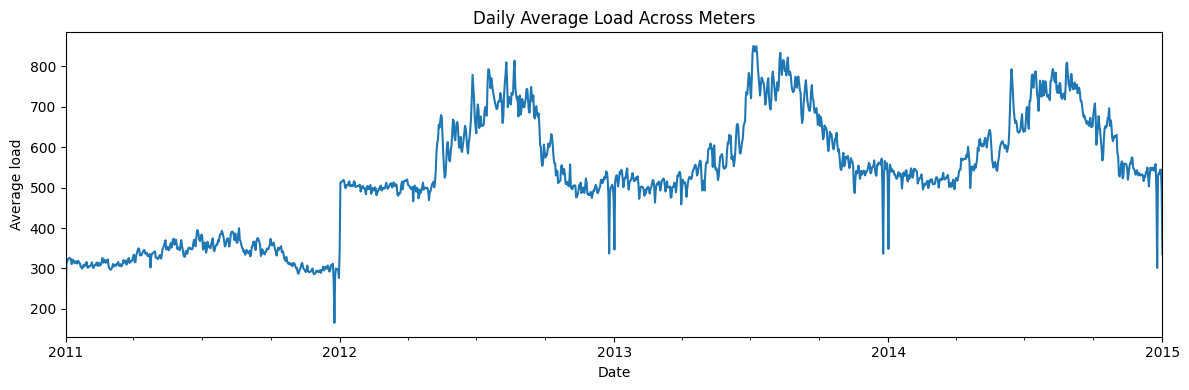

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Ensure 'timestamp' is in datetime format and set it as the index for resampling
df["timestamp"] = pd.to_datetime(df["timestamp"])
daily_average = df.set_index("timestamp").resample("D").mean().mean(axis=1)

# Plotting
ax = daily_average.plot(figsize=(12, 4), title="Daily Average Load Across Meters")
ax.set_xlabel("Date")
ax.set_ylabel("Average load")
plt.tight_layout()
plt.show()

# Pipeline

## 1. Imports and configuration

In [ ]:
from pathlib import Path
import json, pickle, warnings, itertools, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

# ---- EDIT THESE ----
DATA_PATH = Path("Data/Customerwise_data.parquet")  # supports .csv, .parquet, .pq
TIMESTAMP_COL = "timestamp"               # change to your actual timestamp column
TARIFF_INR_PER_KWH = 10.0
MIN_COVERAGE_PER_DAY = 0.90                # 90% of expected 96 readings
MIN_TRAIN_ORIGIN_DAY = 7                   # only predict after 7 complete elapsed days
TEST_FRACTION_OF_DATES = 0.15
VALIDATION_FRACTION_OF_REMAINING_DATES = 0.15
RANDOM_STATE = 42
OUTPUT_DIR = Path("gridvision_artifacts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output directory:", OUTPUT_DIR.resolve())
print("Data path:", DATA_PATH.resolve())

Output directory: C:\Users\Admin\Desktop\GridVision\gridvision_artifacts
Data path: C:\Users\Admin\Desktop\GridVision\Data\customerwise_data.parquet


## 2. Load the raw data

In [ ]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. Set DATA_PATH to your CSV or Parquet file."
    )

suffix = DATA_PATH.suffix.lower()
if suffix == ".csv":
    raw = pd.read_csv(DATA_PATH)
elif suffix in {".parquet", ".pq"}:
    raw = pd.read_parquet(DATA_PATH)
else:
    raise ValueError("Supported formats are CSV and Parquet.")

print("Raw shape:", raw.shape)
display(raw.head())
print("\nColumns:", raw.columns.tolist()[:25], "..." if raw.shape[1] > 25 else "")

Raw shape: (140256, 371)


,timestamp,MT_001,MT_002,MT_003,MT_004,MT_005,MT_006,MT_007,MT_008,MT_009,MT_010,MT_011,MT_012,MT_013,MT_014,MT_015,MT_016,MT_017,MT_018,MT_019,MT_020,MT_021,MT_022,MT_023,MT_024,MT_025,MT_026,MT_027,MT_028,MT_029,MT_030,MT_031,MT_032,MT_033,MT_034,MT_035,MT_036,MT_037,MT_038,MT_039,MT_040,MT_041,MT_042,MT_043,MT_044,MT_045,MT_046,MT_047,MT_048,MT_049,...,MT_321,MT_322,MT_323,MT_324,MT_325,MT_326,MT_327,MT_328,MT_329,MT_330,MT_331,MT_332,MT_333,MT_334,MT_335,MT_336,MT_337,MT_338,MT_339,MT_340,MT_341,MT_342,MT_343,MT_344,MT_345,MT_346,MT_347,MT_348,MT_349,MT_350,MT_351,MT_352,MT_353,MT_354,MT_355,MT_356,MT_357,MT_358,MT_359,MT_360,MT_361,MT_362,MT_363,MT_364,MT_365,MT_366,MT_367,MT_368,MT_369,MT_370
0,2011-01-01 00:15:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,56.760886,0.0,1003.780488,247.095070,177.559913,147.543641,264.115756,644.444444,135.514706,45.08125,129.629630,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2011-01-01 00:30:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,56.760886,0.0,967.195122,243.573944,177.559913,131.321696,264.115756,592.592593,129.632353,50.08750,119.212963,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2011-01-01 00:45:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,55.996944,0.0,991.585366,231.232394,180.827887,136.321696,283.440514,622.222222,125.205882,41.95625,127.314815,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2011-01-01 01:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,58.288770,0.0,991.585366,232.992958,181.917211,130.074813,293.086817,614.814815,125.205882,45.08125,125.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2011-01-01 01:15:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,56.760886,0.0,967.195122,234.753521,177.559913,125.087282,276.977492,607.407407,141.397059,45.08125,122.685185,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Columns: ['timestamp', 'MT_001', 'MT_002', 'MT_003', 'MT_004', 'MT_005', 'MT_006', 'MT_007', 'MT_008', 'MT_009', 'MT_010', 'MT_011', 'MT_012', 'MT_013', 'MT_014', 'MT_015', 'MT_016', 'MT_017', 'MT_018', 'MT_019', 'MT_020', 'MT_021', 'MT_022', 'MT_023', 'MT_024'] ...


## 3. Basic schema checks and timestamp validation

In [ ]:
if TIMESTAMP_COL not in raw.columns:
    raise KeyError(f"TIMESTAMP_COL={TIMESTAMP_COL!r} not found. Available columns: {raw.columns.tolist()}")

raw = raw.copy()
raw[TIMESTAMP_COL] = pd.to_datetime(raw[TIMESTAMP_COL], errors="coerce")
bad_timestamp_rows = int(raw[TIMESTAMP_COL].isna().sum())
raw = raw.dropna(subset=[TIMESTAMP_COL]).sort_values(TIMESTAMP_COL)

print("Rows with invalid timestamps dropped:", bad_timestamp_rows)
print("Timestamp range:", raw[TIMESTAMP_COL].min(), "to", raw[TIMESTAMP_COL].max())
print("Duplicate timestamps:", int(raw[TIMESTAMP_COL].duplicated().sum()))

# Duplicate timestamp policy: stop rather than silently summing or keeping arbitrary rows.
if raw[TIMESTAMP_COL].duplicated().any():
    display(raw.loc[raw[TIMESTAMP_COL].duplicated(keep=False)].head(10))
    raise ValueError(
        "Duplicate timestamps found. Investigate whether they are duplicate records or separate readings "
        "before proceeding; do not silently aggregate them."
    )

meter_cols = [c for c in raw.columns if c != TIMESTAMP_COL]
if not meter_cols:
    raise ValueError("No meter columns found.")

# Convert meter columns to numeric; unparseable values become missing and are reported.
for c in meter_cols:
    raw[c] = pd.to_numeric(raw[c], errors="coerce")

print("Number of meter/customer columns:", len(meter_cols))
display(raw[meter_cols].describe(percentiles=[.5, .9, .95, .99]).T.head(15))

Rows with invalid timestamps dropped: 0
Timestamp range: 2011-01-01 00:15:00 to 2015-01-01 00:00:00
Duplicate timestamps: 0
Number of meter/customer columns: 370


,count,mean,std,min,50%,90%,95%,99%,max
MT_001,140256.0,3.970785,5.983965,0.0,1.269036,15.228426,16.497462,21.573604,48.223350
MT_002,140256.0,20.768480,13.272415,0.0,24.893314,34.850640,38.406828,41.963016,115.220484
MT_003,140256.0,2.918308,11.014456,0.0,1.737619,3.475239,4.344049,79.061685,151.172893
MT_004,140256.0,82.184490,58.248392,0.0,87.398374,152.439024,178.861789,229.674797,321.138211
MT_005,140256.0,37.240309,26.461327,0.0,39.024390,69.512195,80.487805,100.000000,150.000000
MT_006,140256.0,141.227385,98.439984,0.0,157.738095,252.976190,294.642857,383.928571,535.714286
MT_007,140256.0,4.521338,6.485684,0.0,2.826456,9.044658,22.046354,32.786885,44.657999
MT_008,140256.0,191.401476,121.981187,0.0,222.222222,319.865320,346.801347,410.774411,552.188552
MT_009,140256.0,39.975354,29.814595,0.0,40.209790,78.671329,94.405594,117.132867,157.342657
MT_010,140256.0,42.205152,33.401251,0.0,40.860215,88.172043,103.225806,130.107527,198.924731


## 4. Data quality checks

In [ ]:
# For 15-minute interval-energy readings, expected cadence is 15 minutes.
time_diffs = raw[TIMESTAMP_COL].diff().dropna()
print("Most common timestamp gaps:")
display(time_diffs.value_counts().head(10).rename_axis("time_gap").to_frame("count"))

numeric = raw[meter_cols]
quality_summary = pd.DataFrame({
    "missing_count": numeric.isna().sum(),
    "missing_pct": numeric.isna().mean() * 100,
    "zero_count": numeric.eq(0).sum(),
    "negative_count": numeric.lt(0).sum(),
    "max_value": numeric.max(),
    "p99_value": numeric.quantile(.99),
}).sort_values("missing_pct", ascending=False)

display(quality_summary.head(20))
print("Negative meter values:", int(numeric.lt(0).sum().sum()))

# Do not automatically convert zeros to missing: zero can be real consumption.
# Negative values are marked invalid and excluded from consumption sums.
# Extreme spikes are flagged for investigation, not automatically deleted.

Most common timestamp gaps:


,count
time_gap,
0 days 00:15:00,140255


,missing_count,missing_pct,zero_count,negative_count,max_value,p99_value
MT_370,0,0.0,70329,0,30918.918919,24702.702703
MT_001,0,0.0,40743,0,48.223350,21.573604
MT_354,0,0.0,35082,0,391.783567,343.687375
MT_353,0,0.0,35063,0,1056.446440,822.963438
MT_352,0,0.0,35074,0,732.933233,412.603151
MT_351,0,0.0,35068,0,6768.888889,3964.444444
MT_350,0,0.0,35077,0,2288.557214,1666.666667
MT_349,0,0.0,35149,0,589.537223,481.388330
MT_348,0,0.0,102052,0,203.458800,81.383520
MT_347,0,0.0,107424,0,103.092784,7.363770


Negative meter values: 0


## 5. EDA — overview, missingness, consumption distributions

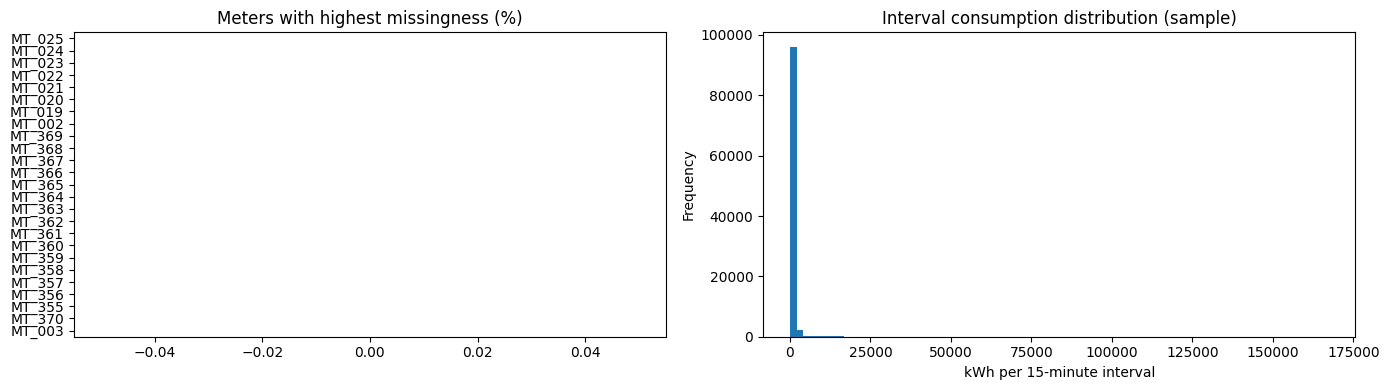

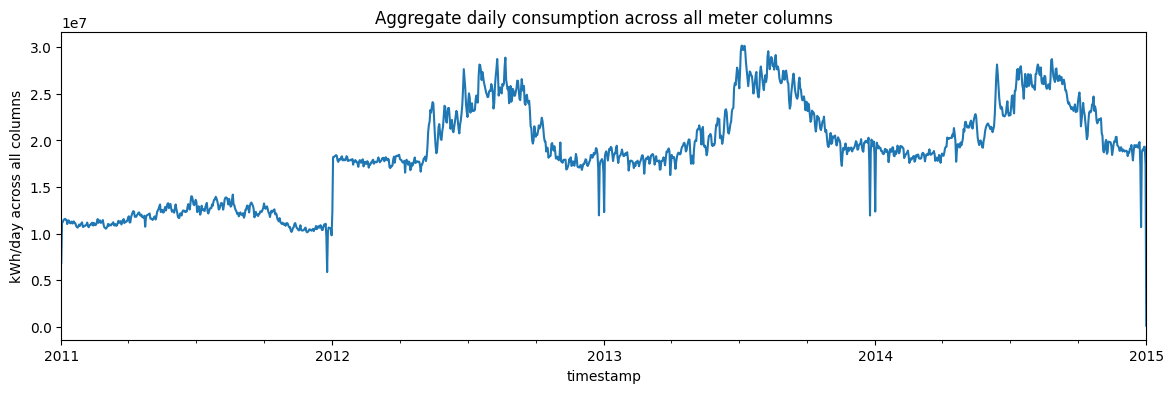

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
quality_summary["missing_pct"].sort_values(ascending=False).head(25).sort_values().plot(
    kind="barh", ax=axes[0], title="Meters with highest missingness (%)"
)
numeric.stack().sample(min(100_000, int(numeric.notna().sum().sum())), random_state=RANDOM_STATE).clip(lower=0).plot(
    kind="hist", bins=80, ax=axes[1], title="Interval consumption distribution (sample)"
)
axes[1].set_xlabel("kWh per 15-minute interval")
plt.tight_layout()
plt.show()

# A compact aggregate series is useful for understanding overall data shape.
wide_plot = raw.set_index(TIMESTAMP_COL)[meter_cols]
overall_interval_kwh = wide_plot.clip(lower=0).sum(axis=1, min_count=1)
overall_daily_kwh = overall_interval_kwh.resample("D").sum(min_count=1)
overall_daily_kwh.plot(figsize=(14, 4), title="Aggregate daily consumption across all meter columns")
plt.ylabel("kWh/day across all columns")
plt.show()

# EDA

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import IsolationForest
from xgboost import XGBRegressor

# 1. Ensure index is a datetime object for time-series operations
df.index = pd.to_datetime(df.index)

# 2. Create the primary target variable: Total Grid Load (sum of all 370 clients)
df['Total_Grid_Load'] = df.sum(axis=1)

# 3. Resample to Hourly intervals to smooth 15-min volatility for the baseline model
df_hourly = df[['Total_Grid_Load']].resample('H').sum()

# 4. Handle any missing data created during resampling
df_hourly = df_hourly.ffill()

C:\Users\Admin\AppData\Local\Temp\ipykernel_10044\1119843353.py:16: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  df_hourly = df[['Total_Grid_Load']].resample('H').sum()


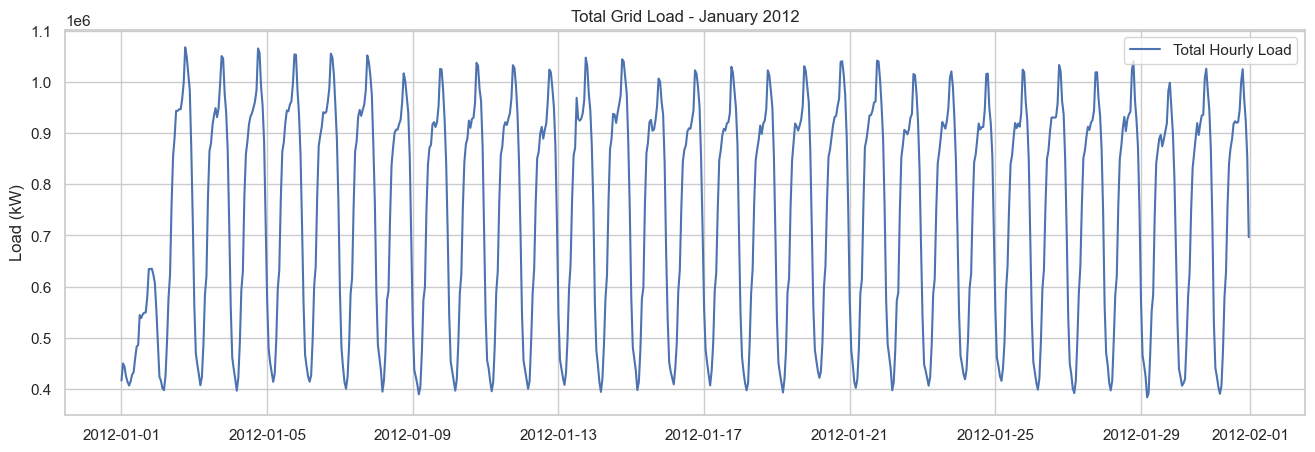

In [ ]:
# Set visualization style
sns.set_theme(style="whitegrid")

# 1. Macro Trend: Plot a one-month slice of total load
plt.figure(figsize=(16, 5))
plt.plot(df_hourly['Total_Grid_Load'].loc['2012-01-01':'2012-01-31'], label='Total Hourly Load')
plt.title("Total Grid Load - January 2012")
plt.ylabel("Load (kW)")
plt.legend()
plt.show()

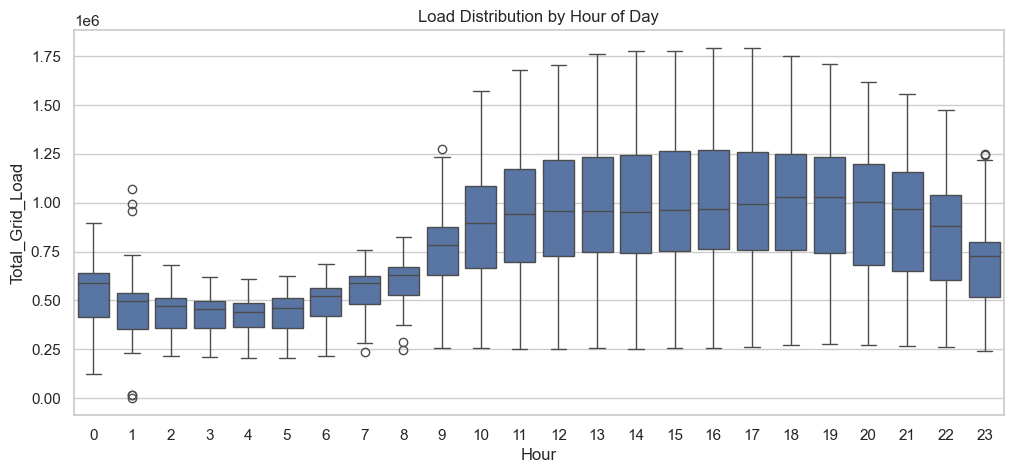

In [ ]:
# 2. Micro Trends: Extract temporal features for EDA
df_eda = df_hourly.copy()
df_eda['Hour'] = df_eda.index.hour
df_eda['DayOfWeek'] = df_eda.index.dayofweek

# 3. Hourly Seasonality Boxplot (identifying peak daily hours)
plt.figure(figsize=(12, 5))
sns.boxplot(data=df_eda, x='Hour', y='Total_Grid_Load')
plt.title("Load Distribution by Hour of Day")
plt.show()

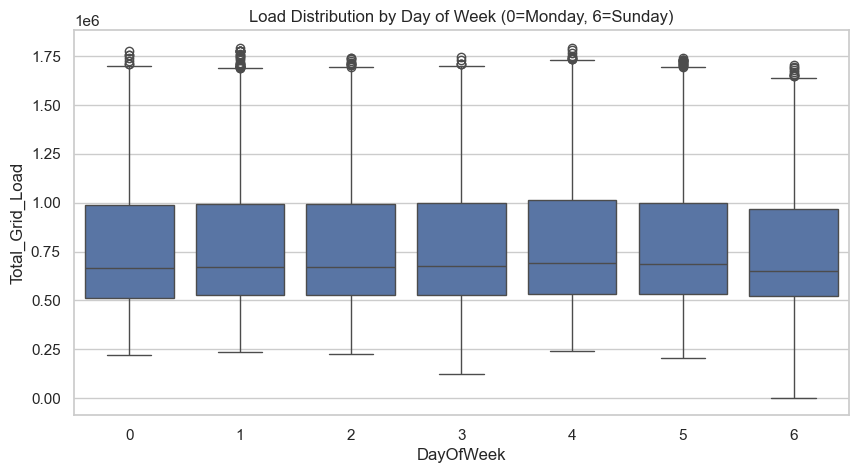

In [ ]:
# 4. Weekly Seasonality Boxplot (identifying weekend drops)
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_eda, x='DayOfWeek', y='Total_Grid_Load')
plt.title("Load Distribution by Day of Week (0=Monday, 6=Sunday)")
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_10044\2382744537.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10.index, y=top_10.values, ax=axes[0], palette='Reds_r')
C:\Users\Admin\AppData\Local\Temp\ipykernel_10044\2382744537.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=bottom_10.index, y=bottom_10.values, ax=axes[1], palette='Blues')


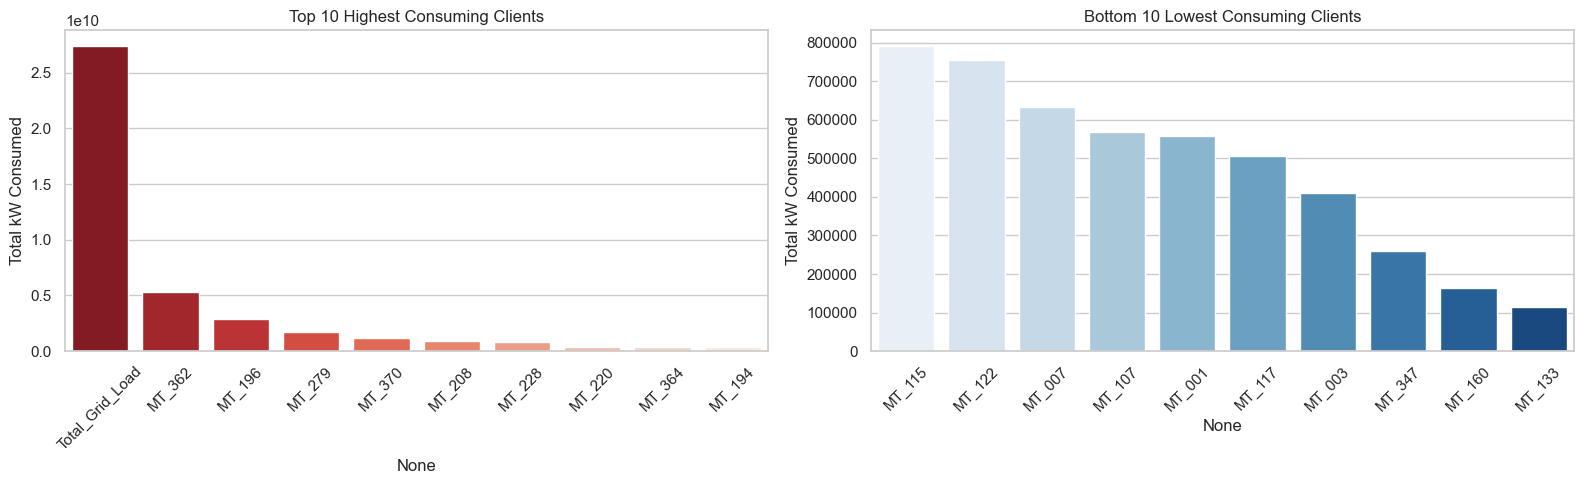

In [ ]:
# ---------------------------------------------------------
# A. PRE-PROCESSING FOR EXTENDED EDA
# ---------------------------------------------------------
df_eda = df.copy()
df_eda['Year'] = df_eda.index.year
df_eda['Month'] = df_eda.index.month
df_eda['Hour'] = df_eda.index.hour
df_eda['DayOfWeek'] = df_eda.index.dayofweek
df_eda['Total_Grid_Load'] = df.sum(axis=1)

# ---------------------------------------------------------
# B. CUSTOMER-WISE ANALYSIS
# ---------------------------------------------------------
# 1. Top 10 vs Bottom 10 Consuming Clients
customer_totals = df.sum(axis=0).sort_values(ascending=False)
top_10 = customer_totals.head(10)
bottom_10 = customer_totals.tail(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(x=top_10.index, y=top_10.values, ax=axes[0], palette='Reds_r')
axes[0].set_title('Top 10 Highest Consuming Clients')
axes[0].set_ylabel('Total kW Consumed')
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(x=bottom_10.index, y=bottom_10.values, ax=axes[1], palette='Blues')
axes[1].set_title('Bottom 10 Lowest Consuming Clients')
axes[1].set_ylabel('Total kW Consumed')
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

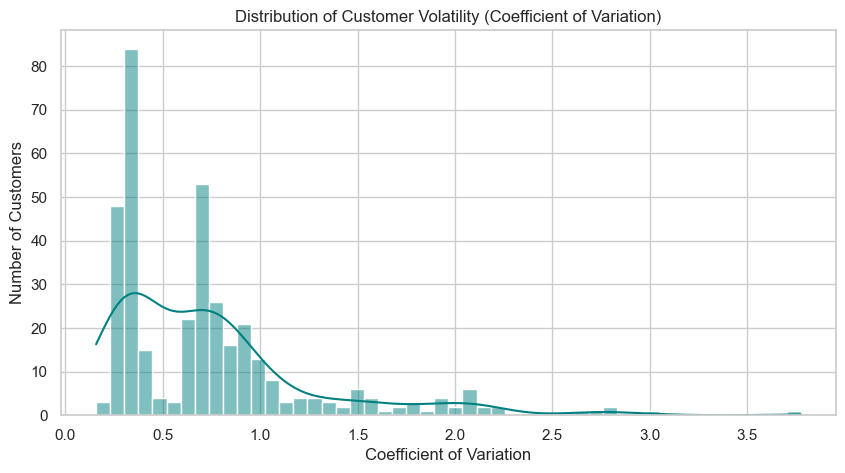

In [ ]:
# 2. Volatility Analysis (Coefficient of Variation)
# High CV = Erratic/volatile usage; Low CV = Stable baseline usage
customer_cv = (df.std(axis=0) / df.mean(axis=0)).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.histplot(customer_cv, bins=50, kde=True, color='teal')
plt.title('Distribution of Customer Volatility (Coefficient of Variation)')
plt.xlabel('Coefficient of Variation')
plt.ylabel('Number of Customers')
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_10044\3556863023.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=yearly_load.index, y=yearly_load.values, palette='viridis')


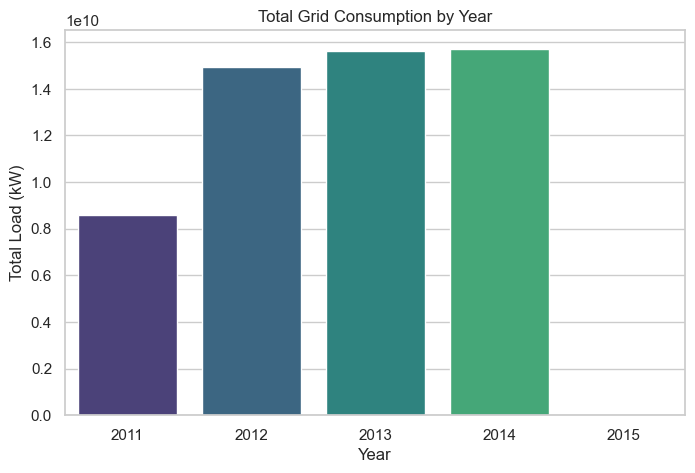

In [ ]:
# ---------------------------------------------------------
# C. TIME-WISE & YEAR-WISE ANALYSIS
# ---------------------------------------------------------
# 1. Yearly Macro Trends
yearly_load = df_eda.groupby('Year')['Total_Grid_Load'].sum()

plt.figure(figsize=(8, 5))
sns.barplot(x=yearly_load.index, y=yearly_load.values, palette='viridis')
plt.title('Total Grid Consumption by Year')
plt.ylabel('Total Load (kW)')
plt.show()

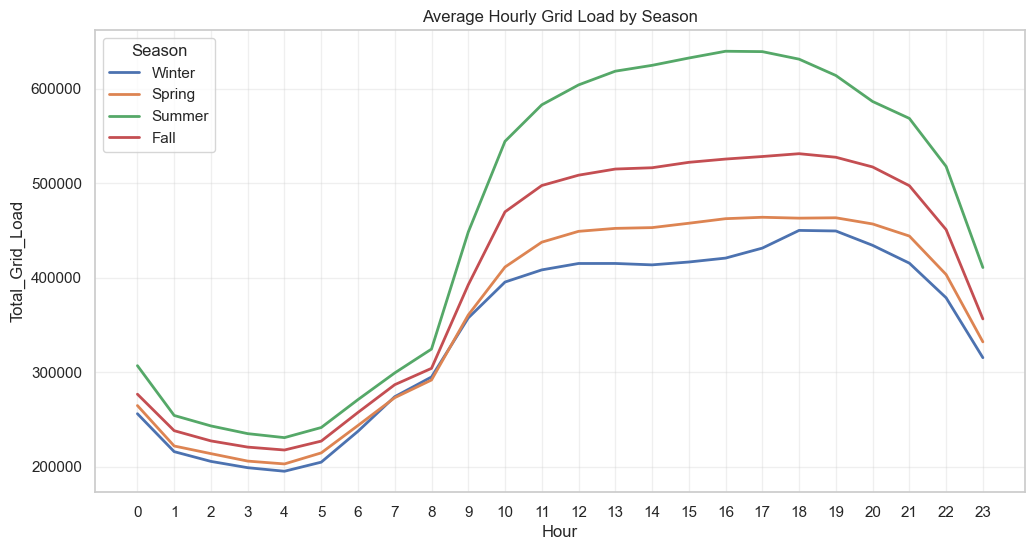

In [ ]:
# 2. Hourly Load Profiles by Season
df_eda['Season'] = df_eda['Month'].apply(lambda x: 'Winter' if x in [12,1,2] else
                                         ('Spring' if x in [3,4,5] else
                                          ('Summer' if x in [6,7,8] else 'Fall')))

plt.figure(figsize=(12, 6))
sns.lineplot(data=df_eda, x='Hour', y='Total_Grid_Load', hue='Season', errorbar=None, lw=2)
plt.title('Average Hourly Grid Load by Season')
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.show()

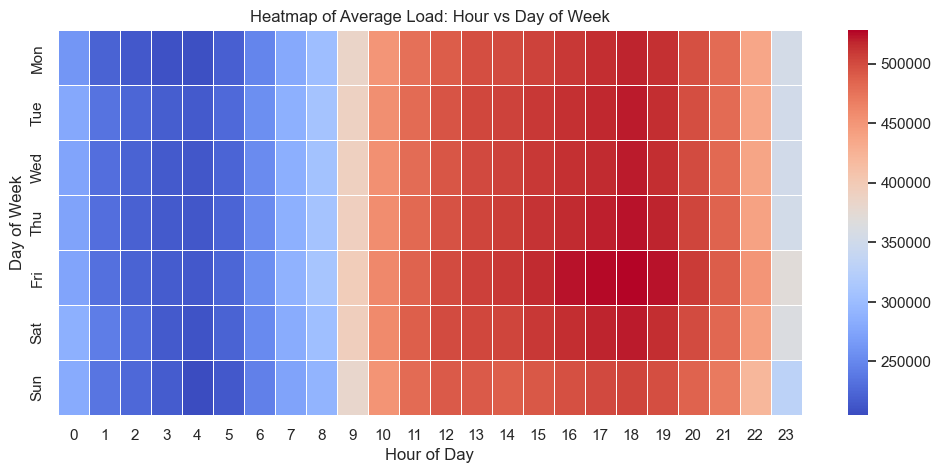

In [ ]:
# 3. Heatmap: Hour of Day vs Day of Week
heatmap_data = df_eda.pivot_table(index='DayOfWeek', columns='Hour', values='Total_Grid_Load', aggfunc='mean')
heatmap_data.index = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

plt.figure(figsize=(12, 5))
sns.heatmap(heatmap_data, cmap='coolwarm', linewidths=.5)
plt.title('Heatmap of Average Load: Hour vs Day of Week')
plt.xlabel('Hour of Day')
plt.ylabel('Day of Week')
plt.show()

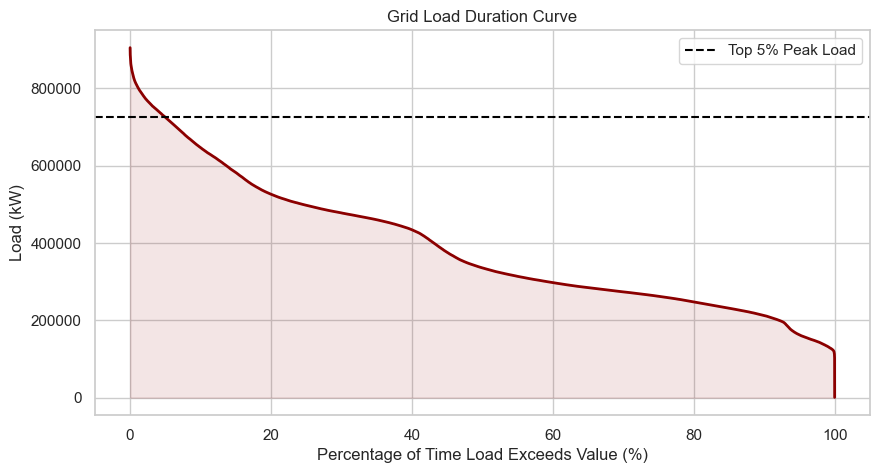

In [ ]:
# ---------------------------------------------------------
# D. ADVANCED GRID ANALYTICS
# ---------------------------------------------------------
# Load Duration Curve (Understanding base load vs peak load)
sorted_load = np.sort(df_eda['Total_Grid_Load'].dropna())[::-1]
percentiles = np.arange(1, len(sorted_load) + 1) / len(sorted_load) * 100

plt.figure(figsize=(10, 5))
plt.plot(percentiles, sorted_load, color='darkred', lw=2)
plt.fill_between(percentiles, sorted_load, color='darkred', alpha=0.1)
plt.title('Grid Load Duration Curve')
plt.xlabel('Percentage of Time Load Exceeds Value (%)')
plt.ylabel('Load (kW)')
plt.axhline(sorted_load[int(len(sorted_load)*0.05)], color='black', linestyle='--', label='Top 5% Peak Load')
plt.legend()
plt.show()

# 6. Convert wide data to long format and validate readings

In [ ]:
# Keep a clean copy of raw source separate from transformations.
raw.to_parquet(OUTPUT_DIR / "raw_source_snapshot.parquet", index=False)

long_df = raw.melt(
    id_vars=[TIMESTAMP_COL],
    value_vars=meter_cols,
    var_name="household_id",
    value_name="interval_kwh"
).rename(columns={TIMESTAMP_COL: "timestamp"})

long_df["interval_kwh_original"] = long_df["interval_kwh"]
long_df["is_missing"] = long_df["interval_kwh"].isna()
long_df["is_negative"] = long_df["interval_kwh"].lt(0)
long_df["is_extreme_global_p99_9"] = (
    long_df["interval_kwh"] > long_df["interval_kwh"].quantile(0.999)
)
# Exclude negative readings from consumption sums, preserving flags for audit.
long_df.loc[long_df["is_negative"], "interval_kwh"] = np.nan
long_df["date"] = long_df["timestamp"].dt.floor("D")

print("Long table shape:", long_df.shape)
display(long_df.head())
display(long_df.groupby("household_id").agg(
    readings=("interval_kwh", "size"),
    valid_readings=("interval_kwh", "count"),
    missing_rate=("interval_kwh", lambda s: s.isna().mean()),
    negative_flag_count=("is_negative", "sum"),
).describe())

Long table shape: (51894720, 8)


,timestamp,household_id,interval_kwh,interval_kwh_original,is_missing,is_negative,is_extreme_global_p99_9,date
0,2011-01-01 00:15:00,MT_001,0.0,0.0,False,False,False,2011-01-01
1,2011-01-01 00:30:00,MT_001,0.0,0.0,False,False,False,2011-01-01
2,2011-01-01 00:45:00,MT_001,0.0,0.0,False,False,False,2011-01-01
3,2011-01-01 01:00:00,MT_001,0.0,0.0,False,False,False,2011-01-01
4,2011-01-01 01:15:00,MT_001,0.0,0.0,False,False,False,2011-01-01


,readings,valid_readings,missing_rate,negative_flag_count
count,370.0,370.0,370.0,370.0
mean,140256.0,140256.0,0.0,0.0
std,0.0,0.0,0.0,0.0
min,140256.0,140256.0,0.0,0.0
25%,140256.0,140256.0,0.0,0.0
50%,140256.0,140256.0,0.0,0.0
75%,140256.0,140256.0,0.0,0.0
max,140256.0,140256.0,0.0,0.0


## 7. Daily aggregation and coverage

In [ ]:
# Because each interval is already kWh, sum the readings. No 0.25 multiplier.
daily = (
    long_df.groupby(["household_id", "date"], observed=True)
    .agg(
        daily_kwh=("interval_kwh", lambda s: s.sum(min_count=1)),
        valid_intervals=("interval_kwh", "count"),
        rows_seen=("interval_kwh", "size"),
        negative_flags=("is_negative", "sum"),
        extreme_flags=("is_extreme_global_p99_9", "sum"),
    )
    .reset_index()
)
daily["coverage_ratio"] = daily["valid_intervals"] / 96.0
daily["is_complete_day"] = daily["coverage_ratio"] >= MIN_COVERAGE_PER_DAY
daily["daily_kwh"] = daily["daily_kwh"].where(daily["daily_kwh"] >= 0)

# Important: incomplete days are not treated as fully observed days.
# For training, only use rows whose recent/current-cycle aggregates have acceptable coverage.
display(daily.head())
print("Daily rows:", len(daily))
print("Complete-day rate:", round(daily["is_complete_day"].mean(), 4))
print("Daily coverage distribution:")
display(daily["coverage_ratio"].describe())

,household_id,date,daily_kwh,valid_intervals,rows_seen,negative_flags,extreme_flags,coverage_ratio,is_complete_day
0,MT_001,2011-01-01,0.0,95,95,0,0,0.989583,True
1,MT_001,2011-01-02,0.0,96,96,0,0,1.000000,True
2,MT_001,2011-01-03,0.0,96,96,0,0,1.000000,True
3,MT_001,2011-01-04,0.0,96,96,0,0,1.000000,True
4,MT_001,2011-01-05,0.0,96,96,0,0,1.000000,True


Daily rows: 540940
Complete-day rate: 0.9993
Daily coverage distribution:


count    540940.000000
mean          0.999316
std           0.025873
min           0.010417
25%           1.000000
50%           1.000000
75%           1.000000
max           1.000000
Name: coverage_ratio, dtype: float64

## 8. EDA — daily usage patterns

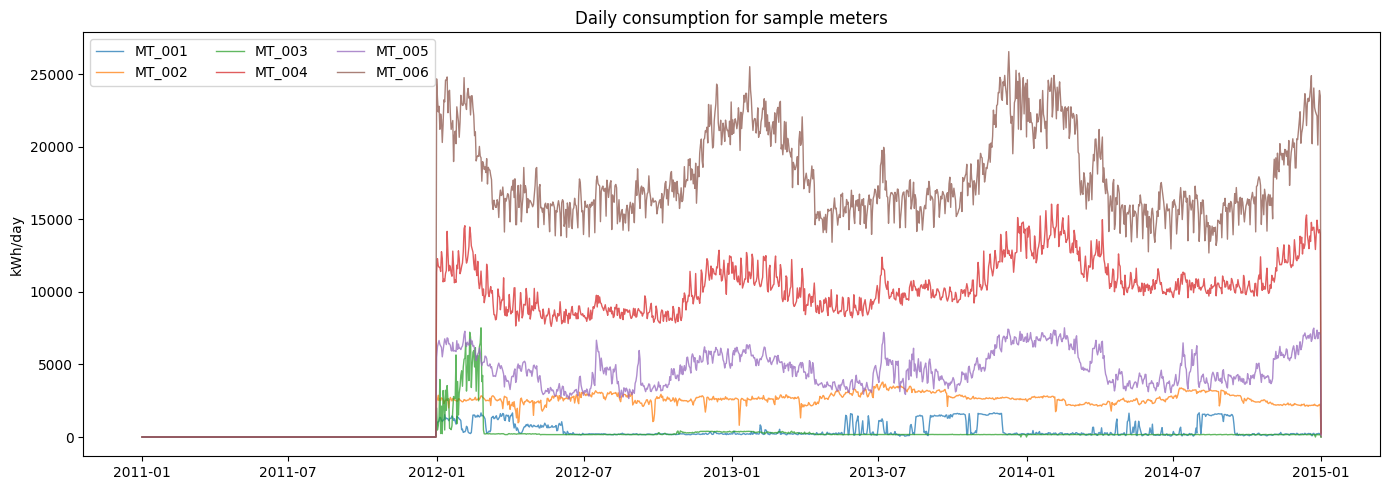

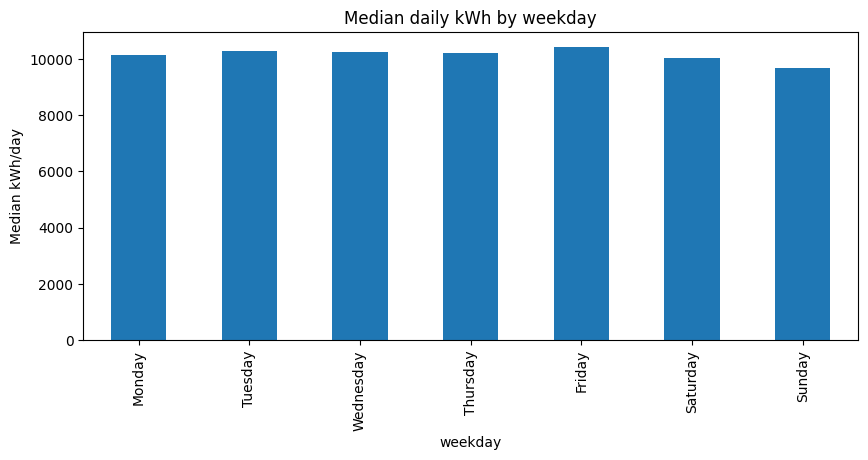

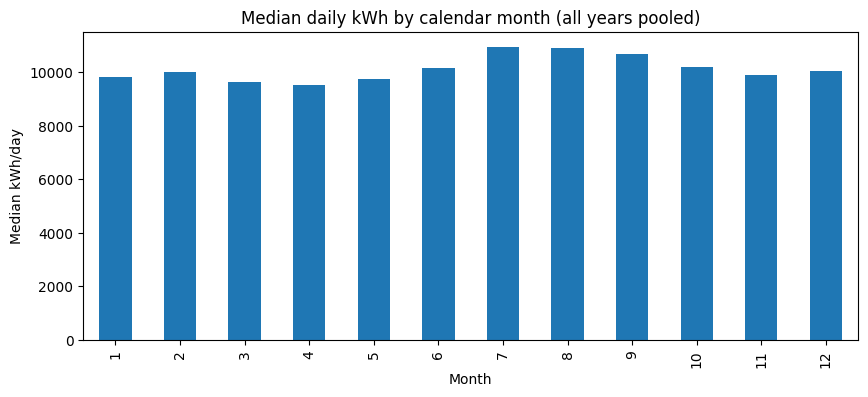

In [ ]:
sample_households = daily["household_id"].drop_duplicates().head(min(6, daily["household_id"].nunique())).tolist()
fig, ax = plt.subplots(figsize=(14, 5))
for hid in sample_households:
    tmp = daily[daily["household_id"] == hid].sort_values("date")
    ax.plot(tmp["date"], tmp["daily_kwh"], alpha=.75, linewidth=1, label=str(hid))
ax.set_title("Daily consumption for sample meters")
ax.set_ylabel("kWh/day")
ax.legend(ncol=3)
plt.tight_layout()
plt.show()

eda = daily.dropna(subset=["daily_kwh"]).copy()
eda["weekday"] = eda["date"].dt.day_name()
eda["month"] = eda["date"].dt.month
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
eda.groupby("weekday")["daily_kwh"].median().reindex(weekday_order).plot(
    kind="bar", figsize=(10, 4), title="Median daily kWh by weekday"
)
plt.ylabel("Median kWh/day")
plt.show()

eda.groupby(eda["date"].dt.month)["daily_kwh"].median().plot(
    kind="bar", figsize=(10, 4), title="Median daily kWh by calendar month (all years pooled)"
)
plt.xlabel("Month")
plt.ylabel("Median kWh/day")
plt.show()

## 9. Build forecast-origin training examples (leakage-safe)

Each row represents one household at the end of a date inside a calendar month:
- Features use readings available **up to and including the forecast-origin date**.
- The target is consumption on **future dates only**, from the next day through month-end.
- Origins before the end of Day 7 are excluded.
- Actual current-cycle consumption is tracked separately and added to the predicted remaining kWh for the bill estimate.

For simplicity and auditability, the initial implementation requires a valid daily reading for the origin date and enough observed history. Missing/incomplete days can be improved later with more nuanced coverage-aware features.

In [ ]:
daily = daily.sort_values(["household_id", "date"]).reset_index(drop=True)
daily["month_start"] = daily["date"].dt.to_period("M").dt.start_time
daily["month_end"] = daily["date"].dt.to_period("M").dt.end_time.dt.floor("D")
daily["day_of_month"] = daily["date"].dt.day
daily["day_of_week"] = daily["date"].dt.dayofweek
daily["month_num"] = daily["date"].dt.month
daily["is_weekend"] = daily["day_of_week"].isin([5, 6]).astype(int)

# Missing days are made explicit per household, which makes lag/rolling windows calendar-day based.
all_dates = pd.date_range(daily["date"].min(), daily["date"].max(), freq="D")
households = daily["household_id"].drop_duplicates().tolist()
full_index = pd.MultiIndex.from_product([households, all_dates], names=["household_id", "date"])
daily_full = daily.set_index(["household_id", "date"]).reindex(full_index).reset_index()

# Restore calendar and coverage columns after reindex.
daily_full["month_start"] = daily_full["date"].dt.to_period("M").dt.start_time
daily_full["month_end"] = daily_full["date"].dt.to_period("M").dt.end_time.dt.floor("D")
daily_full["day_of_month"] = daily_full["date"].dt.day
daily_full["day_of_week"] = daily_full["date"].dt.dayofweek
daily_full["month_num"] = daily_full["date"].dt.month
daily_full["is_weekend"] = daily_full["day_of_week"].isin([5, 6]).astype(int)
daily_full["coverage_ratio"] = daily_full["coverage_ratio"].fillna(0.0)
daily_full["valid_intervals"] = daily_full["valid_intervals"].fillna(0)
daily_full["is_complete_day"] = daily_full["is_complete_day"].fillna(False)

def build_origin_features(g):
    g = g.sort_values("date").copy()
    s = g["daily_kwh"]
    # Shifted windows avoid using the current day's consumption for prior-day lag features;
    # current day's consumption is allowed because the forecast is made at end of that day.
    g["lag_1d"] = s.shift(1)
    g["lag_7d"] = s.shift(7)
    g["lag_14d"] = s.shift(14)
    g["rolling_mean_3d"] = s.rolling(3, min_periods=2).mean()
    g["rolling_mean_7d"] = s.rolling(7, min_periods=5).mean()
    g["rolling_mean_14d"] = s.rolling(14, min_periods=8).mean()
    g["rolling_std_7d"] = s.rolling(7, min_periods=5).std()
    g["rolling_mean_30d"] = s.rolling(30, min_periods=10).mean()
    g["rolling_std_30d"] = s.rolling(30, min_periods=10).std()
    g["recent_vs_month_mean"] = g["rolling_mean_7d"] - g["rolling_mean_30d"]
    g["recent_vs_prior_week"] = g["rolling_mean_7d"] - s.shift(7).rolling(7, min_periods=4).mean()

    # Household profile features computed only from history through the origin date.
    g["history_mean"] = s.expanding(min_periods=7).mean()
    g["history_median"] = s.expanding(min_periods=7).median()
    g["history_p90"] = s.expanding(min_periods=7).quantile(.90)

    # Current calendar-cycle consumption through the origin, not the whole month.
    g["actual_cycle_kwh_so_far"] = s.where(g["month_start"].eq(g["month_start"].shift(1)), 0).groupby(g["month_start"]).cumsum()
    # The groupby cumsum above needs the first day of each month included; recompute robustly.
    g["actual_cycle_kwh_so_far"] = s.groupby(g["month_start"]).cumsum()

    g["elapsed_days"] = g["day_of_month"]
    g["days_remaining"] = (g["month_end"] - g["date"]).dt.days
    g["day_of_year"] = g["date"].dt.dayofyear
    g["year"] = g["date"].dt.year
    g["sin_doy"] = np.sin(2 * np.pi * g["day_of_year"] / 365.25)
    g["cos_doy"] = np.cos(2 * np.pi * g["day_of_year"] / 365.25)
    g["coverage_today"] = g["coverage_ratio"]
    g["coverage_7d_mean"] = g["coverage_ratio"].rolling(7, min_periods=1).mean()
    g["valid_intervals_7d"] = g["valid_intervals"].rolling(7, min_periods=1).sum()
    return g

features_daily = (
    daily_full.groupby("household_id", group_keys=False, observed=True)
    .apply(build_origin_features)
    .reset_index(drop=True)
)

FEATURE_COLS = [
    "lag_1d", "lag_7d", "lag_14d",
    "rolling_mean_3d", "rolling_mean_7d", "rolling_mean_14d",
    "rolling_std_7d", "rolling_mean_30d", "rolling_std_30d",
    "recent_vs_month_mean", "recent_vs_prior_week",
    "history_mean", "history_median", "history_p90",
    "actual_cycle_kwh_so_far", "elapsed_days", "days_remaining",
    "day_of_week", "is_weekend", "month_num", "day_of_year", "year",
    "sin_doy", "cos_doy", "coverage_today", "coverage_7d_mean", "valid_intervals_7d"
]
print("Feature count:", len(FEATURE_COLS))
display(features_daily[["household_id", "date"] + FEATURE_COLS].tail())

Feature count: 27


,household_id,date,lag_1d,lag_7d,lag_14d,rolling_mean_3d,rolling_mean_7d,rolling_mean_14d,rolling_std_7d,rolling_mean_30d,rolling_std_30d,recent_vs_month_mean,recent_vs_prior_week,history_mean,history_median,history_p90,actual_cycle_kwh_so_far,elapsed_days,days_remaining,day_of_week,is_weekend,month_num,day_of_year,year,sin_doy,cos_doy,coverage_today,coverage_7d_mean,valid_intervals_7d
540935,MT_370,2014-12-28,1.438865e+06,1.682757e+06,7.775676e+05,1.394505e+06,1.266170e+06,1.494131e+06,439074.571243,1.555876e+06,344020.248484,-289705.791506,-455922.779923,835607.381456,0.000000,1.986941e+06,4.334762e+07,28,3,6,1,12,362,2014,-0.055879,0.998438,1.000000,1.000000,672.0
540936,MT_370,2014-12-29,1.553189e+06,1.738595e+06,1.550378e+06,1.599514e+06,1.275869e+06,1.512425e+06,451814.365583,1.561342e+06,346736.301584,-285473.616474,-473111.969112,836272.822926,0.000000,1.986465e+06,4.515411e+07,29,2,0,0,12,363,2014,-0.038696,0.999251,1.000000,1.000000,672.0
540937,MT_370,2014-12-30,1.806486e+06,1.594216e+06,1.795459e+06,1.742414e+06,1.314919e+06,1.517575e+06,493778.846802,1.567389e+06,350548.968132,-252470.270270,-405312.741313,836979.189189,0.000000,1.985989e+06,4.702168e+07,30,1,1,0,12,364,2014,-0.021501,0.999769,1.000000,1.000000,672.0
540938,MT_370,2014-12-31,1.867568e+06,7.256757e+05,1.885946e+06,1.679982e+06,1.406378e+06,1.480429e+06,420266.207796,1.554034e+06,350331.963169,-147655.855856,-148100.386100,837341.210204,0.000000,1.985514e+06,4.838757e+07,31,0,2,0,12,365,2014,-0.004301,0.999991,1.000000,1.000000,672.0
540939,MT_370,2015-01-01,1.365892e+06,6.211892e+05,1.661243e+06,1.080198e+06,1.318656e+06,1.362278e+06,625464.580527,1.495371e+06,447349.754862,-176714.800515,-87243.243243,836773.353792,3567.567568,1.985130e+06,7.135135e+03,1,30,3,0,1,1,2015,0.017202,0.999852,0.010417,0.858631,577.0


## 10. Create the future-consumption target

In [ ]:
# Fast, vectorized target generation
examples = features_daily.sort_values(
    ["household_id", "date"]
).copy()

group_cols = ["household_id", "month_start"]
groups = examples.groupby(group_cols, sort=False)

# Sum of consumption for the entire month
monthly_total = groups["daily_kwh"].transform("sum")

# Cumulative consumption up to and including the forecast date
cumulative = groups["daily_kwh"].cumsum()

# Target: consumption strictly after the forecast date
examples["target_remaining_kwh"] = monthly_total - cumulative

# Count incomplete/missing days in the future only
bad_day = (
    ~examples["is_complete_day"].fillna(False)
    | examples["daily_kwh"].isna()
).astype(int)

bad_days_so_far = (
    bad_day.groupby(
        [examples[c] for c in group_cols],
        sort=False
    ).cumsum()
)

total_bad_days = bad_day.groupby(
    [examples[c] for c in group_cols],
    sort=False
).transform("sum")

future_bad_days = total_bad_days - bad_days_so_far

examples["target_future_days"] = examples["days_remaining"]
examples["future_target_complete"] = future_bad_days.eq(0)

# Exclude invalid targets and apply the 7-day onboarding rule
first_seen = (
    daily.groupby("household_id")["date"]
    .min()
    .rename("first_seen_date")
)

examples = examples.join(first_seen, on="household_id")

examples["elapsed_since_first_seen"] = (
    examples["date"] - examples["first_seen_date"]
).dt.days + 1

examples = examples[
    (examples["day_of_month"] >= MIN_TRAIN_ORIGIN_DAY)
    & (examples["elapsed_since_first_seen"] >= MIN_TRAIN_ORIGIN_DAY)
    & examples["is_complete_day"].eq(True)
    & examples["future_target_complete"]
    & examples["target_remaining_kwh"].notna()
    & (examples["days_remaining"] > 0)
].copy()

examples = examples.replace([np.inf, -np.inf], np.nan)

print("Usable training examples:", len(examples))
print("Date range:", examples["date"].min(), "to", examples["date"].max())
print("Households represented:", examples["household_id"].nunique())

display(
    examples[
        [
            "household_id",
            "date",
            "actual_cycle_kwh_so_far",
            "target_remaining_kwh",
            "days_remaining",
        ]
    ].head()
)

Usable training examples: 416250
Date range: 2011-01-07 00:00:00 to 2014-12-30 00:00:00
Households represented: 370


,household_id,date,actual_cycle_kwh_so_far,target_remaining_kwh,days_remaining
6,MT_001,2011-01-07,0.0,0.0,24
7,MT_001,2011-01-08,0.0,0.0,23
8,MT_001,2011-01-09,0.0,0.0,22
9,MT_001,2011-01-10,0.0,0.0,21
10,MT_001,2011-01-11,0.0,0.0,20


## 11. Baselines

In [ ]:
def safe_baseline_predictions(df):
    # Baseline A: average daily use observed so far × remaining days.
    elapsed = df["elapsed_days"].clip(lower=1)
    rate = df["actual_cycle_kwh_so_far"] / elapsed
    return np.maximum(0, rate * df["days_remaining"])

examples["baseline_recent_rate"] = safe_baseline_predictions(examples)
print("Baseline rows ready:", len(examples))

Baseline rows ready: 416250


## 12. Chronological train / validation / test split

In [ ]:
examples = examples.sort_values(["date", "household_id"]).reset_index(drop=True)
unique_dates = np.array(sorted(examples["date"].dropna().unique()))
if len(unique_dates) < 10:
    raise ValueError("Not enough distinct forecast dates for chronological train/validation/test evaluation.")

n_dates = len(unique_dates)
test_n = max(1, int(round(n_dates * TEST_FRACTION_OF_DATES)))
val_n = max(1, int(round((n_dates - test_n) * VALIDATION_FRACTION_OF_REMAINING_DATES)))
train_end_idx = n_dates - test_n - val_n
if train_end_idx < 3:
    raise ValueError("Too few dates for train/validation/test split. Reduce validation/test fractions only if justified.")

train_dates = set(unique_dates[:train_end_idx])
val_dates = set(unique_dates[train_end_idx:n_dates-test_n])
test_dates = set(unique_dates[n_dates-test_n:])

train_df = examples[examples["date"].isin(train_dates)].copy()
val_df = examples[examples["date"].isin(val_dates)].copy()
test_df = examples[examples["date"].isin(test_dates)].copy()

print("Train:", train_df["date"].min(), "to", train_df["date"].max(), "| rows", len(train_df))
print("Validation:", val_df["date"].min(), "to", val_df["date"].max(), "| rows", len(val_df))
print("Test:", test_df["date"].min(), "to", test_df["date"].max(), "| rows", len(test_df))
assert train_df["date"].max() < val_df["date"].min() < test_df["date"].min()

Train: 2011-01-07 00:00:00 to 2013-11-22 00:00:00 | rows 300810
Validation: 2013-11-23 00:00:00 to 2014-05-26 00:00:00 | rows 52910
Test: 2014-05-27 00:00:00 to 2014-12-30 00:00:00 | rows 62530


## 13. Define models and evaluation metrics

In [ ]:
def make_model(name, params=None):
    params = params or {}
    if name == "Ridge":
        estimator = Ridge(**params)
        steps = [("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("model", estimator)]
    elif name == "RandomForest":
        estimator = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **params)
        steps = [("imputer", SimpleImputer(strategy="median")), ("model", estimator)]
    elif name == "HistGradientBoosting":
        estimator = HistGradientBoostingRegressor(random_state=RANDOM_STATE, **params)
        steps = [("imputer", SimpleImputer(strategy="median")), ("model", estimator)]
    elif name == "LightGBM":
        from lightgbm import LGBMRegressor
        estimator = LGBMRegressor(random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1, **params)
        steps = [("imputer", SimpleImputer(strategy="median")), ("model", estimator)]
    elif name == "XGBoost":
        from xgboost import XGBRegressor
        estimator = XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1, objective="reg:squarederror", **params)
        steps = [("imputer", SimpleImputer(strategy="median")), ("model", estimator)]
    else:
        raise ValueError(name)
    return Pipeline(steps)

def evaluate_remaining_and_bill(df, pred_remaining, tariff=TARIFF_INR_PER_KWH):
    pred_remaining = np.clip(np.asarray(pred_remaining, dtype=float), 0, None)
    actual_remaining = df["target_remaining_kwh"].to_numpy(dtype=float)
    actual_so_far = df["actual_cycle_kwh_so_far"].to_numpy(dtype=float)
    actual_month_kwh = actual_so_far + actual_remaining
    pred_month_kwh = actual_so_far + pred_remaining
    actual_bill = actual_month_kwh * tariff
    pred_bill = pred_month_kwh * tariff
    return {
        "remaining_MAE_kWh": mean_absolute_error(actual_remaining, pred_remaining),
        "remaining_RMSE_kWh": mean_squared_error(actual_remaining, pred_remaining) ** 0.5,
        "month_end_MAE_kWh": mean_absolute_error(actual_month_kwh, pred_month_kwh),
        "month_end_MAE_INR": mean_absolute_error(actual_bill, pred_bill),
        "month_end_RMSE_INR": mean_squared_error(actual_bill, pred_bill) ** 0.5,
        "month_end_WAPE_pct": 100 * np.sum(np.abs(actual_month_kwh - pred_month_kwh)) / max(np.sum(np.abs(actual_month_kwh)), 1e-9),
    }

X_train, y_train = train_df[FEATURE_COLS], train_df["target_remaining_kwh"]
X_val, y_val = val_df[FEATURE_COLS], val_df["target_remaining_kwh"]
X_test, y_test = test_df[FEATURE_COLS], test_df["target_remaining_kwh"]

## 14. Compare baseline and untuned candidate models

In [ ]:
!pip install tqdm

In [ ]:
from tqdm.auto import tqdm
import time

candidate_specs = {
    "Ridge": {},
    "RandomForest": {
        "n_estimators": 250,
        "min_samples_leaf": 3,
        "max_features": 0.8
    },
    "HistGradientBoosting": {
        "max_iter": 250,
        "learning_rate": 0.06,
        "max_leaf_nodes": 15,
        "l2_regularization": 1.0
    },
}

# Optional models
try:
    import lightgbm
    candidate_specs["LightGBM"] = {
        "n_estimators": 300, "learning_rate": 0.05,
        "num_leaves": 31, "max_depth": -1
    }
except ImportError:
    print("LightGBM unavailable; skipping.")

try:
    import xgboost
    candidate_specs["XGBoost"] = {
        "n_estimators": 300, "learning_rate": 0.05,
        "max_depth": 6, "subsample": 0.9,
        "colsample_bytree": 0.9
    }
except ImportError:
    print("XGBoost unavailable; skipping.")

comparison = []

# Step 1: Baseline
print("Evaluating baseline...")
comparison.append({
    "model": "Baseline_recent_rate",
    **evaluate_remaining_and_bill(
        val_df, val_df["baseline_recent_rate"]
    )
})

fitted_candidates = {}

# Step 2: Fit and evaluate models with progress bar
with tqdm(
    candidate_specs.items(),
    total=len(candidate_specs),
    desc="Training models",
    unit="model",
    dynamic_ncols=True
) as pbar:

    for name, params in pbar:
        pbar.set_postfix_str(f"Fitting {name}")
        start = time.time()

        try:
            pipe = make_model(name, params)

            pbar.set_postfix_str(f"{name}: training")
            pipe.fit(X_train, y_train)

            pbar.set_postfix_str(f"{name}: predicting")
            pred = pipe.predict(X_val)

            pbar.set_postfix_str(f"{name}: evaluating")
            metrics = evaluate_remaining_and_bill(val_df, pred)

            fitted_candidates[name] = pipe
            comparison.append({
                "model": name,
                **metrics
            })

            tqdm.write(
                f"✓ {name} completed in {time.time() - start:.1f}s"
            )

        except Exception as e:
            tqdm.write(f"✗ {name} failed: {e}")

# Step 3: Results
comparison_df = pd.DataFrame(comparison).sort_values(
    "month_end_MAE_INR"
)

display(comparison_df)

Evaluating baseline...


Training models:   0%|          | 0/5 [00:00<?, ?model/s, Ridge: training]

Training models:  20%|██        | 1/5 [00:01<00:07,  1.77s/model, RandomForest: training]

✓ Ridge completed in 1.8s


Training models:  40%|████      | 2/5 [05:17<09:20, 186.70s/model, HistGradientBoosting: training]

...

Training models:  80%|████████  | 4/5 [05:27<01:04, 64.43s/model, XGBoost: training]    

✓ LightGBM completed in 4.2s


Training models: 100%|██████████| 5/5 [05:36<00:00, 67.30s/model, XGBoost: evaluating]

✓ XGBoost completed in 9.4s


,model,remaining_MAE_kWh,remaining_RMSE_kWh,month_end_MAE_kWh,month_end_MAE_INR,month_end_RMSE_INR,month_end_WAPE_pct
0,Baseline_recent_rate,30069.518948,235654.481426,30069.518948,300695.189484,2.356545e+06,1.905358
2,RandomForest,30672.532913,239644.348268,30672.532913,306725.329125,2.396443e+06,1.943568
5,XGBoost,35128.661394,235876.664850,35128.661394,351286.613938,2.358767e+06,2.225931
4,LightGBM,38226.927839,273595.930572,38226.927839,382269.278394,2.735959e+06,2.422252
3,HistGradientBoosting,49998.117749,392061.567108,49998.117749,499981.177489,3.920616e+06,3.168135
1,Ridge,61661.081187,327892.485887,61661.081187,616610.811867,3.278925e+06,3.907159


## 15. Hyperparameter tuning with chronological validation windows

In [ ]:
!pip install torch


  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.4.2-py3-none-any.whl.metadata (6.3 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
    --------------------------------------- 2.9/124.1 MB 18.6 MB/s eta 0:00:07
   -- ------------------------------------- 7.6/124.1 MB 21.3 MB/s eta 0:00:06
   ----- ---------------------------------- 16.0/124.1 MB 27.9 MB/s eta 0:00:04
   ------ --------------------------------- 19.1/124.1 MB 23.7 MB/s eta 0:00:05
   ------ --------------------------------- 19.9/124.1 MB 24.7 MB/s eta 0:00:05
   -------- ------------------------------- 26.7/124.1 MB 21.7 MB/s eta 0:00:05
   --------- ------------------------------ 30.9/124.1 MB 21.3 MB/s eta 0:00:05
   ----------- ---------------------------- 34.6/124.1 MB 22.2 MB/s eta 0:00:05
   ------------- ---------------------

In [ ]:
from tqdm.auto import tqdm
import time
import itertools
import numpy as np
import pandas as pd

# Check GPU availability
import torch

USE_CUDA = torch.cuda.is_available()
print("CUDA available:", USE_CUDA)

if USE_CUDA:
    print("GPU:", torch.cuda.get_device_name(0))


def chronological_date_folds(frame, n_splits=3, min_train_fraction=0.5):
    dates = np.array(sorted(frame["date"].dropna().unique()))

    if len(dates) < n_splits + 3:
        return []

    folds = []
    start_train_end = max(3, int(len(dates) * min_train_fraction))
    remaining = len(dates) - start_train_end
    block = max(1, remaining // n_splits)

    for i in range(n_splits):
        train_end = start_train_end + i * block
        val_end = len(dates) if i == n_splits - 1 else min(
            len(dates), train_end + block
        )

        tr_dates = set(dates[:train_end])
        va_dates = set(dates[train_end:val_end])

        if tr_dates and va_dates:
            folds.append((tr_dates, va_dates))

    return folds


def tune_candidates(trainval_df):
    available = trainval_df.attrs.get("available_models", [])

    grids = {
        # "RandomForest": [
        #     {
        #         "n_estimators": n,
        #         "max_depth": depth,
        #         "min_samples_leaf": leaf,
        #         "max_features": 0.8
        #     }
        #     for n, depth, leaf in itertools.product(
        #         [100, 200], [12, 24], [2, 5]
        #     )
        # ]
    }

    if "XGBoost" in available:
        grids["XGBoost"] = [
            {
                "n_estimators": n,
                "learning_rate": lr,
                "max_depth": depth,
                "subsample": 0.9,
                "colsample_bytree": 0.9,
                **(
                    {"tree_method": "hist", "device": "cuda"}
                    if USE_CUDA else {"tree_method": "hist"}
                )
            }
            for n, lr, depth in itertools.product(
                [100, 200], [0.03, 0.06], [4, 6]
            )
        ]

    if "LightGBM" in available:
        grids["LightGBM"] = [
            {
                "n_estimators": n,
                "learning_rate": lr,
                "num_leaves": leaves,
                "max_depth": -1,
                **({"device": "gpu"} if USE_CUDA else {})
            }
            for n, lr, leaves in itertools.product(
                [100, 200], [0.03, 0.06], [15, 31]
            )
        ]

    folds = chronological_date_folds(trainval_df, n_splits=3)

    if not folds:
        print("Not enough dates for chronological tuning.")
        return pd.DataFrame(), None, grids

    fold_data = []

    for tr_dates, va_dates in folds:
        tr = trainval_df[trainval_df["date"].isin(tr_dates)]
        va = trainval_df[trainval_df["date"].isin(va_dates)]

        if not tr.empty and not va.empty:
            fold_data.append((tr, va))

    if not fold_data:
        print("No valid training/validation folds.")
        return pd.DataFrame(), None, grids

    total_configs = sum(len(params) for params in grids.values())
    total_fits = total_configs * len(fold_data)

    print("Models:", list(grids.keys()))
    print("Parameter configurations:", total_configs)
    print("Total model fits:", total_fits)
    print("GPU acceleration applies to supported XGBoost/LightGBM models.")

    results = []
    start_all = time.time()

    with tqdm(
        total=total_fits,
        desc="Hyperparameter tuning",
        unit="fit",
        dynamic_ncols=True
    ) as pbar:

        for name, param_list in grids.items():
            for config_num, params in enumerate(param_list, start=1):
                fold_scores = []
                config_start = time.time()

                for fold_idx, (tr, va) in enumerate(fold_data, start=1):
                    pbar.set_postfix_str(
                        f"{name} | config {config_num}/{len(param_list)} "
                        f"| fold {fold_idx}/{len(fold_data)}"
                    )

                    try:
                        model = make_model(name, params)

                        model.fit(
                            tr[FEATURE_COLS],
                            tr["target_remaining_kwh"]
                        )

                        pred = np.clip(
                            model.predict(va[FEATURE_COLS]), 0, None
                        )

                        score = evaluate_remaining_and_bill(
                            va, pred
                        )["month_end_MAE_INR"]

                        fold_scores.append(score)

                    except Exception as e:
                        tqdm.write(
                            f"Failed: {name}, {params}, "
                            f"fold {fold_idx}: {e}"
                        )
                    finally:
                        pbar.update(1)

                if fold_scores:
                    results.append({
                        "model": name,
                        "params": params,
                        "cv_mean_month_end_MAE_INR": float(
                            np.mean(fold_scores)
                        ),
                        "cv_std_month_end_MAE_INR": float(
                            np.std(fold_scores)
                        ),
                        "folds_scored": len(fold_scores),
                        "config_time_sec": round(
                            time.time() - config_start, 1
                        )
                    })

    results_df = pd.DataFrame(results)

    if results_df.empty:
        print("No configurations completed successfully.")
        return results_df, None, grids

    results_df = results_df.sort_values(
        "cv_mean_month_end_MAE_INR"
    ).reset_index(drop=True)

    best = results_df.iloc[0]

    print(f"\nTuning completed in {(time.time() - start_all) / 60:.1f} minutes.")

    return results_df, best, grids


trainval_df = (
    pd.concat([train_df, val_df], ignore_index=True)
    .sort_values(["date", "household_id"])
)

trainval_df.attrs["available_models"] = list(candidate_specs.keys())

tuning_results, best_tuning_row, searched_grids = tune_candidates(trainval_df)

display(tuning_results.head(15))

if best_tuning_row is not None:
    print("\nBest model:", best_tuning_row["model"])
    print("Best parameters:", best_tuning_row["params"])
    print(
        "Best CV month-end MAE (₹):",
        round(best_tuning_row["cv_mean_month_end_MAE_INR"], 2)
    )

CUDA available: False
Models: ['XGBoost', 'LightGBM']
Parameter configurations: 16
Total model fits: 48
GPU acceleration applies to supported XGBoost/LightGBM models.


Hyperparameter tuning: 100%|██████████| 48/48 [02:45<00:00,  3.45s/fit, LightGBM | config 8/8 | fold 3/3]


Tuning completed in 2.8 minutes.


,model,params,cv_mean_month_end_MAE_INR,cv_std_month_end_MAE_INR,folds_scored,config_time_sec
0,XGBoost,"{'n_estimators': 200, 'learning_rate': 0.06, '...",1.043613e+06,487993.228870,3,14.5
1,LightGBM,"{'n_estimators': 200, 'learning_rate': 0.06, '...",1.046929e+06,514258.431971,3,7.8
2,LightGBM,"{'n_estimators': 200, 'learning_rate': 0.06, '...",1.081958e+06,588000.692701,3,11.6
3,LightGBM,"{'n_estimators': 200, 'learning_rate': 0.03, '...",1.088293e+06,502124.942270,3,11.1
4,LightGBM,"{'n_estimators': 200, 'learning_rate': 0.03, '...",1.094353e+06,578320.952804,3,9.8
5,XGBoost,"{'n_estimators': 200, 'learning_rate': 0.03, '...",1.105069e+06,626744.011583,3,13.9
6,LightGBM,"{'n_estimators': 100, 'learning_rate': 0.06, '...",1.105124e+06,508351.524669,3,5.5
7,LightGBM,"{'n_estimators': 100, 'learning_rate': 0.06, '...",1.110887e+06,580113.725208,3,7.0
8,XGBoost,"{'n_estimators': 200, 'learning_rate': 0.06, '...",1.116816e+06,661312.435717,3,13.6
9,XGBoost,"{'n_estimators': 100, 'learning_rate': 0.06, '...",1.132094e+06,649888.710895,3,9.2



Best model: XGBoost
Best parameters: {'n_estimators': 200, 'learning_rate': 0.06, 'max_depth': 4, 'subsample': 0.9, 'colsample_bytree': 0.9, 'tree_method': 'hist'}
Best CV month-end MAE (₹): 1043613.01


## 16. Refit selected model and evaluate once on the untouched test period

In [ ]:
if best_tuning_row is not None:
    best_name = best_tuning_row["model"]
    best_params = best_tuning_row["params"]
else:
    # Fallback when there are too few dates for multi-fold tuning:
    # select the best untuned validation model, excluding the test period.
    best_name = comparison_df.loc[comparison_df["model"] != "Baseline_recent_rate"].iloc[0]["model"]
    best_params = candidate_specs[best_name]

final_train_df = pd.concat([train_df, val_df], ignore_index=True).sort_values(["date", "household_id"])
final_model = make_model(best_name, best_params)
final_model.fit(final_train_df[FEATURE_COLS], final_train_df["target_remaining_kwh"])

test_pred = np.clip(final_model.predict(X_test), 0, None)
test_metrics = evaluate_remaining_and_bill(test_df, test_pred)
baseline_metrics = evaluate_remaining_and_bill(test_df, test_df["baseline_recent_rate"])
print("Selected model:", best_name)
print("Parameters:", best_params)
print("\nHeld-out test metrics:")
display(pd.DataFrame([
    {"model": "Selected_ML", **test_metrics},
    {"model": "Baseline_recent_rate", **baseline_metrics},
]))

Selected model: XGBoost
Parameters: {'n_estimators': 200, 'learning_rate': 0.06, 'max_depth': 4, 'subsample': 0.9, 'colsample_bytree': 0.9, 'tree_method': 'hist'}

Held-out test metrics:


,model,remaining_MAE_kWh,remaining_RMSE_kWh,month_end_MAE_kWh,month_end_MAE_INR,month_end_RMSE_INR,month_end_WAPE_pct
0,Selected_ML,67011.937035,479788.595636,67011.937035,670119.370347,4.797886e+06,3.509085
1,Baseline_recent_rate,43300.662772,542332.439453,43300.662772,433006.627716,5.423324e+06,2.267442


## 17. Diagnostic plots and error breakdowns

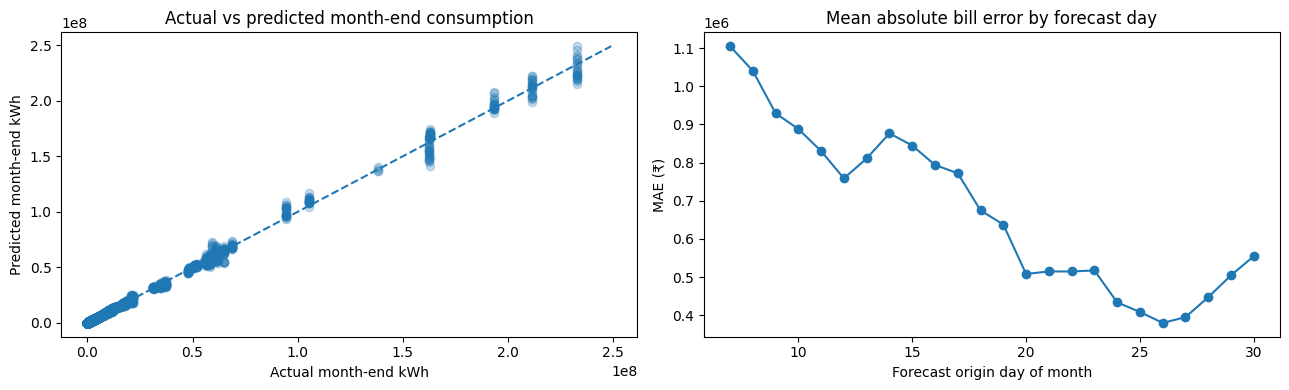

,count,mean,median
household_id,,,
MT_362,169,6.226163e+07,5.502036e+07
MT_370,169,2.297997e+07,1.373396e+07
MT_196,169,1.727157e+07,1.019758e+07
MT_279,169,1.451549e+07,9.628497e+06
MT_208,169,9.818705e+06,5.188626e+06
MT_228,169,5.113552e+06,3.881880e+06
MT_339,169,4.086388e+06,2.304475e+06
MT_364,169,3.703578e+06,2.245750e+06
MT_224,169,2.614233e+06,1.479307e+06


In [ ]:
test_results = test_df[["household_id", "date", "month_start", "month_end", "day_of_month",
                        "actual_cycle_kwh_so_far", "target_remaining_kwh", "days_remaining"]].copy()
test_results["predicted_remaining_kwh"] = test_pred
test_results["actual_month_end_kwh"] = test_results["actual_cycle_kwh_so_far"] + test_results["target_remaining_kwh"]
test_results["predicted_month_end_kwh"] = test_results["actual_cycle_kwh_so_far"] + test_results["predicted_remaining_kwh"]
test_results["actual_bill_inr"] = test_results["actual_month_end_kwh"] * TARIFF_INR_PER_KWH
test_results["predicted_bill_inr"] = test_results["predicted_month_end_kwh"] * TARIFF_INR_PER_KWH
test_results["absolute_bill_error_inr"] = (test_results["actual_bill_inr"] - test_results["predicted_bill_inr"]).abs()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(test_results["actual_month_end_kwh"], test_results["predicted_month_end_kwh"], alpha=.25)
lims = [
    min(test_results["actual_month_end_kwh"].min(), test_results["predicted_month_end_kwh"].min()),
    max(test_results["actual_month_end_kwh"].max(), test_results["predicted_month_end_kwh"].max())
]
axes[0].plot(lims, lims, linestyle="--")
axes[0].set_xlabel("Actual month-end kWh")
axes[0].set_ylabel("Predicted month-end kWh")
axes[0].set_title("Actual vs predicted month-end consumption")

test_results.groupby("day_of_month")["absolute_bill_error_inr"].mean().plot(ax=axes[1], marker="o")
axes[1].set_title("Mean absolute bill error by forecast day")
axes[1].set_xlabel("Forecast origin day of month")
axes[1].set_ylabel("MAE (₹)")
plt.tight_layout()
plt.show()

display(test_results.groupby("household_id")["absolute_bill_error_inr"].agg(["count", "mean", "median"]).sort_values("mean", ascending=False).head(15))

## 18. Save the trained model, feature schema, and metadata

In [ ]:
# Bundle feature order and assumptions with the model so the API can validate inputs.
artifact = {
    "model": final_model,
    "model_name": best_name,
    "model_params": best_params,
    "feature_columns": FEATURE_COLS,
    "target_name": "target_remaining_kwh",
    "tariff_inr_per_kwh": TARIFF_INR_PER_KWH,
    "timestamp_col": TIMESTAMP_COL,
    "interval_minutes": 15,
    "interval_unit": "kWh per 15-minute interval",
    "daily_aggregation": "sum",
    "billing_cycle": "calendar_month",
    "minimum_elapsed_days_before_prediction": MIN_TRAIN_ORIGIN_DAY,
    "minimum_daily_coverage_ratio": MIN_COVERAGE_PER_DAY,
    "test_metrics": test_metrics,
    "baseline_test_metrics": baseline_metrics,
    "training_date_min": str(final_train_df["date"].min()),
    "training_date_max": str(final_train_df["date"].max()),
    "created_utc": pd.Timestamp.utcnow().isoformat(),
    "notes": [
        "Prediction target is future consumption after forecast-origin date through calendar month-end.",
        "Month-end bill is calculated outside the model from actual_cycle_kwh_so_far + predicted_remaining_kwh.",
        "₹10/kWh is a prototype tariff and excludes fixed charges, taxes, slabs and utility adjustments.",
        "The feature-generation logic must be versioned and reused by the API."
    ]
}

model_path = OUTPUT_DIR / "gridvision_month_end_model.pkl"
with open(model_path, "wb") as f:
    pickle.dump(artifact, f, protocol=pickle.HIGHEST_PROTOCOL)

metadata_path = OUTPUT_DIR / "gridvision_model_metadata.json"
metadata = {k: v for k, v in artifact.items() if k not in {"model", "feature_columns"}}
metadata["feature_columns"] = FEATURE_COLS
# Convert NumPy scalar / non-JSON values safely.
def json_safe(obj):
    if isinstance(obj, dict):
        return {str(k): json_safe(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [json_safe(v) for v in obj]
    if isinstance(obj, (np.integer,)): return int(obj)
    if isinstance(obj, (np.floating,)): return float(obj)
    if isinstance(obj, (pd.Timestamp,)): return obj.isoformat()
    if isinstance(obj, (np.ndarray,)): return obj.tolist()
    if isinstance(obj, (np.bool_,)): return bool(obj)
    if isinstance(obj, Path): return str(obj)
    if obj is None or isinstance(obj, (str, int, float, bool)): return obj
    return str(obj)

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(json_safe(metadata), f, indent=2)

print("Saved model:", model_path.resolve())
print("Saved metadata:", metadata_path.resolve())

Saved model: C:\Users\Admin\Desktop\GridVision\gridvision_artifacts\gridvision_month_end_model.pkl
Saved metadata: C:\Users\Admin\Desktop\GridVision\gridvision_artifacts\gridvision_model_metadata.json


## 19. Reload test — verify the `.pkl` is usable

In [ ]:
with open(model_path, "rb") as f:
    loaded_artifact = pickle.load(f)

loaded_model = loaded_artifact["model"]
loaded_features = loaded_artifact["feature_columns"]
assert loaded_features == FEATURE_COLS

sample_X = test_df[loaded_features].head(10)
pred_before = final_model.predict(sample_X)
pred_after = loaded_model.predict(sample_X)
print("Maximum reload prediction difference:", float(np.max(np.abs(pred_before - pred_after))))
print("Sample predicted remaining kWh:", np.clip(pred_after, 0, None)[:5])

Maximum reload prediction difference: 0.0
Sample predicted remaining kWh: [    0.        0.        0.    32812.965     0.   ]
